# Bayesian Logistic Regression: CAVI vs Reparameterization

Run in order: **Data → Model → Variational Inference → Evaluation → Visualization → Prediction**.

Compare **coordinate-ascent VI using a quadratic likelihood bound** with **reparameterization-based VI** on the same Bayesian logistic-regression model.

The main question is: **how can we approximate the posterior through optimization?**

Format adapted from the saved `week4_bayesian_logistic_mcmc_hmc_v3.ipynb`; the current GitHub notebook could not be retrieved. Dependencies: `torch`, `matplotlib`. Install if needed using `%pip install torch matplotlib`.

## 1. Data

Generate a small binary classification dataset.

We use one input feature and an intercept, so the parameter vector is
$$w=(w_0,w_1)^\top\in\mathbb R^2.$$
Keeping the posterior two-dimensional lets us visualize the posterior and the variational approximations.

In [2]:
import torch
import matplotlib.pyplot as plt

# ============================================================
# 1. Generate binary classification data (same setup as template)
# ============================================================
torch.manual_seed(0)
N = 80
x = 1.3 * torch.randn(N, 1)
phi = torch.cat([torch.ones(N, 1), x], dim=1)
w_true = torch.tensor([-0.5, 2.0])
prob_true = torch.sigmoid(phi @ w_true)
y = torch.bernoulli(prob_true)
D = phi.shape[1]

# Convert after generation to retain the template's seeded dataset.
x, phi, y, w_true = [a.double() for a in (x, phi, y, w_true)]
torch.set_num_threads(1)
print(f'Number of observations: {N}')
print(f'Number of parameters: {D}')

Number of observations: 80
Number of parameters: 2


### View the dataset

Each point is an observation $(x_i,y_i)$.

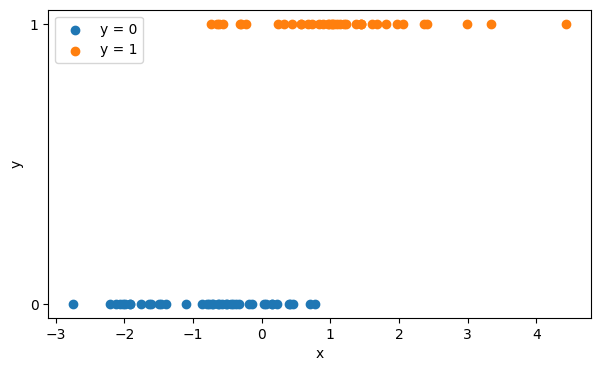

In [3]:
plt.figure(figsize=(7, 4))
plt.scatter(x[y == 0], y[y == 0], label='y = 0')
plt.scatter(x[y == 1], y[y == 1], label='y = 1')
plt.xlabel('x'); plt.ylabel('y'); plt.yticks([0, 1])
plt.legend(); plt.show()

## 2. Model

For Bayesian logistic regression,
$$p(y_i=1\mid x_i,w)=\sigma(w^\top\phi_i).$$
Use the same Gaussian prior as the template:
$$p(w)=\mathcal N(0,\sigma_0^2 I),\qquad\sigma_0=3.$$
The unnormalized log posterior is
$$\log\widetilde p(w\mid\mathcal D)=-\frac{w^Tw}{2\sigma_0^2}+\sum_{i=1}^N[y_i a_i-\log(1+e^{a_i})],\qquad a_i=\phi_i^T w.$$
Both methods below approximate the **same posterior**, using a **full-covariance Gaussian** $q(w)=\mathcal N(m,S)$.

In [4]:
# ============================================================
# 2. Bayesian logistic regression posterior
# ============================================================
prior_std = 3.0
alpha = 1.0 / prior_std**2
I = torch.eye(D, dtype=phi.dtype)

def log_likelihood(w):
    # w has shape (..., D); return one log likelihood per weight vector.
    logits = w @ phi.T
    return (y * logits - torch.nn.functional.softplus(logits)).sum(dim=-1)

def log_posterior(w):
    return log_likelihood(w) - 0.5*alpha*(w*w).sum(dim=-1)

def gaussian_kl(m, L):
    # q=N(m, LL^T), p=N(0, prior_std^2 I); L has positive diagonal.
    return 0.5*(alpha*((L*L).sum()+(m*m).sum()) - D
                + 2*D*torch.log(torch.tensor(prior_std, dtype=m.dtype))
                - 2*torch.log(torch.diag(L)).sum())

### Posterior distribution

Because $w\in\mathbb R^2$, we can draw posterior contours. The values below are scaled to a maximum of one for visualization; they are **not a normalized posterior density**.

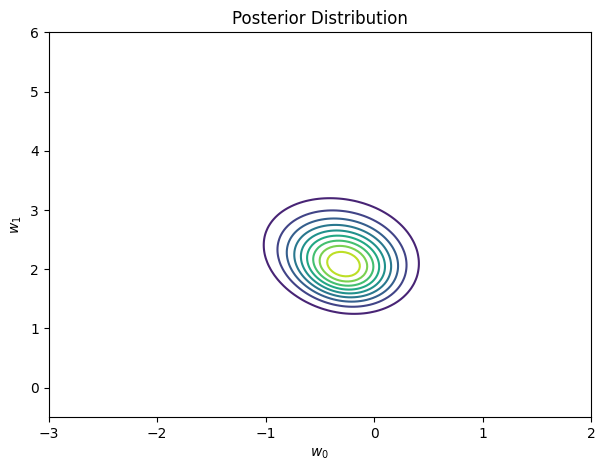

In [5]:
# ============================================================
# Posterior grid for visualization
# ============================================================
w0_values = torch.linspace(-3.0, 2.0, 180, dtype=phi.dtype)
w1_values = torch.linspace(-0.5, 6.0, 180, dtype=phi.dtype)
W0, W1 = torch.meshgrid(w0_values, w1_values, indexing='xy')
w_grid = torch.stack([W0.flatten(), W1.flatten()], dim=1)
with torch.no_grad():
    log_grid = log_posterior(w_grid).reshape(W0.shape)
    posterior = torch.exp(log_grid-log_grid.max())
plt.figure(figsize=(7, 5))
plt.contour(W0, W1, posterior, levels=10)
plt.xlabel(r'$w_0$'); plt.ylabel(r'$w_1$')
plt.title('Posterior Distribution'); plt.show()

## 3. Variational Inference

Instead of constructing a Markov chain, optimize a Gaussian approximation:
$$\mathcal L(q)=\mathbb E_q[\log p(y\mid X,w)]-\mathrm{KL}(q(w)\|p(w)).$$

### 3.1 Coordinate-Ascent Variational Inference (CAVI)

Logistic regression is nonconjugate. To obtain closed-form updates, introduce the **Jaakkola–Jordan quadratic bound**:
$$\log\sigma(t)\geq\log\sigma(\xi)+\frac{t-\xi}{2}-\lambda(\xi)(t^2-\xi^2),\qquad\lambda(\xi)=\frac{\tanh(\xi/2)}{4\xi}.$$
Using one local parameter $\xi_i$ per observation, alternate
$$S^{-1}=\alpha I+2\Phi^T\operatorname{diag}(\lambda(\xi_i))\Phi,\qquad m=S\Phi^T(y-1/2),$$
$$\xi_i=\sqrt{\phi_i^T(S+mm^T)\phi_i},\qquad\alpha=\sigma_0^{-2}.$$
This optimizes a **lower bound to the original ELBO**, rather than evaluating the logistic expectation exactly. These updates also correspond to CAVI in a Pólya–Gamma augmented representation.

[Jaakkola & Jordan (1997)](https://proceedings.mlr.press/r1/jaakkola97a.html) · [Augmented-model interpretation](https://arxiv.org/abs/1711.06999)

In [6]:
# ============================================================
# 3.1 CAVI: Gaussian update + local bound-parameter update
# ============================================================
def jj_lambda(xi):
    safe_xi = xi.clamp_min(1e-10)
    return torch.where(xi > 1e-8, torch.tanh(safe_xi/2)/(4*safe_xi),
                       torch.full_like(xi, 0.125))

def cavi(max_iter=500, tol=1e-9):
    xi = torch.ones(N, dtype=phi.dtype)
    bounds, means = [], [torch.zeros(D, dtype=phi.dtype)]
    for t in range(max_iter):
        # Update q(w) given the local parameters.
        precision = alpha*I + 2*phi.T @ (jj_lambda(xi)[:, None]*phi)
        precision_chol = torch.linalg.cholesky(precision)
        S = torch.cholesky_inverse(precision_chol)
        m = torch.cholesky_solve((phi.T @ (y-0.5))[:, None], precision_chol).squeeze(1)
        # Update local parameters given q(w).
        mu = phi @ m
        second_moment = mu**2 + ((phi @ S)*phi).sum(dim=1)
        xi = torch.sqrt(second_moment)
        L = torch.linalg.cholesky(S)
        bound = (-torch.nn.functional.softplus(-xi)-xi/2+(y-0.5)*mu
                 -jj_lambda(xi)*(second_moment-xi**2)).sum()-gaussian_kl(m, L)
        bounds.append(bound.item())
        means.append(m.clone())
        if len(bounds) > 1 and abs(bounds[-1]-bounds[-2]) < tol:
            break
    return m, S, torch.tensor(bounds), torch.stack(means)

m_cavi, S_cavi, cavi_bound, cavi_means = cavi()
L_cavi = torch.linalg.cholesky(S_cavi)
assert torch.all(torch.diff(cavi_bound) >= -1e-5)
print(f'CAVI iterations: {len(cavi_bound)}')
print(f'Posterior mean: {m_cavi.numpy()}')

CAVI iterations: 35
Posterior mean: [-0.2866918   2.13298594]


### 3.2 Reparameterization Trick

Write $S=LL^T$ and transform independent standard-normal noise:
$$\epsilon^{(s)}\sim\mathcal N(0,I),\qquad w^{(s)}=m+L\epsilon^{(s)}.$$
Then estimate the ELBO by
$$\widehat{\mathcal L}=\frac1M\sum_{s=1}^M\log p(y\mid X,w^{(s)})-\mathrm{KL}(q\|p).$$
PyTorch differentiates through $w=m+L\epsilon$. We maximize the ELBO by minimizing its negative with Adam.

The Gaussian KL is analytic. Only the expected log likelihood is sampled. The data likelihood is **summed over observations**, then averaged over weight samples.

In [7]:
# ============================================================
# 3.2 Reparameterization VI with PyTorch autograd
# ============================================================
def make_cholesky(raw_L):
    return torch.tril(raw_L, diagonal=-1) + torch.diag(torch.exp(torch.diag(raw_L)))

def reparameterization_vi(num_steps=2500, num_samples=64, learning_rate=0.02):
    torch.manual_seed(1)
    m = torch.zeros(D, dtype=phi.dtype, requires_grad=True)
    raw_L = torch.zeros(D, D, dtype=phi.dtype, requires_grad=True)
    optimizer = torch.optim.Adam([m, raw_L], lr=learning_rate)
    elbos, means = [], [m.detach().clone()]
    for t in range(num_steps):
        optimizer.zero_grad()
        L = make_cholesky(raw_L)
        eps = torch.randn(num_samples, D, dtype=phi.dtype)
        w_samples = m + eps @ L.T
        elbo = log_likelihood(w_samples).mean() - gaussian_kl(m, L)
        (-elbo).backward()
        optimizer.step()
        # Gradually reduce the learning rate to limit late fluctuations.
        optimizer.param_groups[0]['lr'] = learning_rate / (1 + (t+1)/1000)
        elbos.append(elbo.detach().item())
        means.append(m.detach().clone())
    L = make_cholesky(raw_L).detach()
    return m.detach().clone(), L @ L.T, torch.tensor(elbos), torch.stack(means)

m_rp, S_rp, rp_elbo, rp_means = reparameterization_vi()
L_rp = torch.linalg.cholesky(S_rp)
assert torch.isfinite(rp_elbo).all()
print(f'Adam steps: {len(rp_elbo)}')
print(f'Posterior mean: {m_rp.numpy()}')

Adam steps: 2500
Posterior mean: [-0.30229939  2.20799731]


## 4. Evaluation

Compare posterior means, standard deviations, and estimates of the **same original logistic ELBO**. The Monte Carlo standard error describes numerical estimation error, not posterior uncertainty.

CAVI's training bound and the reparameterization ELBO are different objectives; do not interpret their training values as directly equivalent.

CAVI
  posterior mean: [-0.2866918   2.13298594]
  posterior std : [0.26252943 0.23878478]
  logistic ELBO : -34.006 (MC SE 0.003)
Reparameterization
  posterior mean: [-0.30229939  2.20799731]
  posterior std : [0.33140464 0.45125982]
  logistic ELBO : -33.687 (MC SE 0.007)


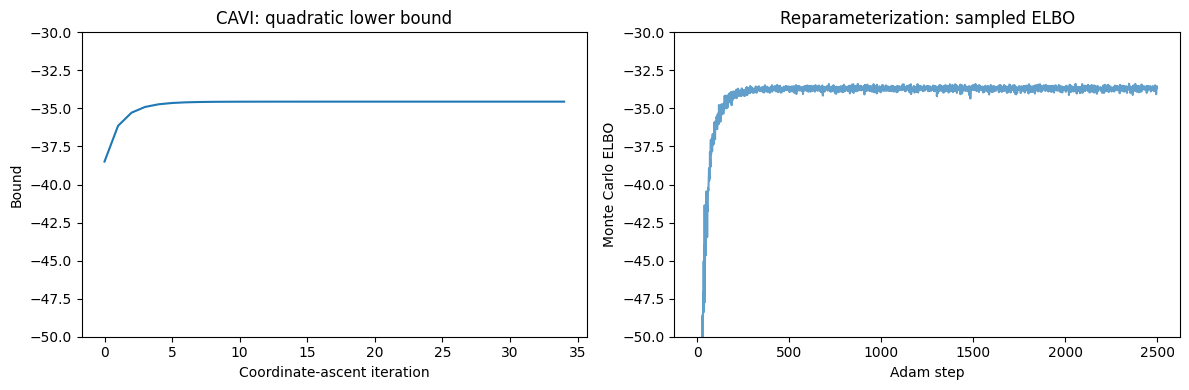

In [8]:
# ============================================================
# 4. Evaluation using independent, shared diagnostic noise
# ============================================================
torch.manual_seed(10)
eps_eval = torch.randn(20000, D, dtype=phi.dtype)

for name, m, L in [('CAVI', m_cavi, L_cavi), ('Reparameterization', m_rp, L_rp)]:
    with torch.no_grad():
        values = log_likelihood(m + eps_eval @ L.T)
        estimated_elbo = values.mean() - gaussian_kl(m, L)
        se = values.std() / len(values)**0.5
    print(name)
    print('  posterior mean:', m.numpy())
    print('  posterior std :', torch.sqrt(torch.diag(L @ L.T)).numpy())
    print(f'  logistic ELBO : {estimated_elbo:.3f} (MC SE {se:.3f})')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(cavi_bound)
axes[0].set_ylim([-50,-30])
axes[0].set(title='CAVI: quadratic lower bound', xlabel='Coordinate-ascent iteration', ylabel='Bound')
axes[1].plot(rp_elbo, alpha=.7)
axes[1].set_ylim([-50,-30])
axes[1].set(title='Reparameterization: sampled ELBO', xlabel='Adam step', ylabel='Monte Carlo ELBO')
plt.tight_layout(); plt.show()

## 5. Visualization

Compare posterior contours with the fitted Gaussian approximations. Both contours are separately scaled to peak at one, so they show **shape**, not relative density normalization.

The paths below track **optimization of the variational mean**; they are not MCMC trajectories or posterior samples.

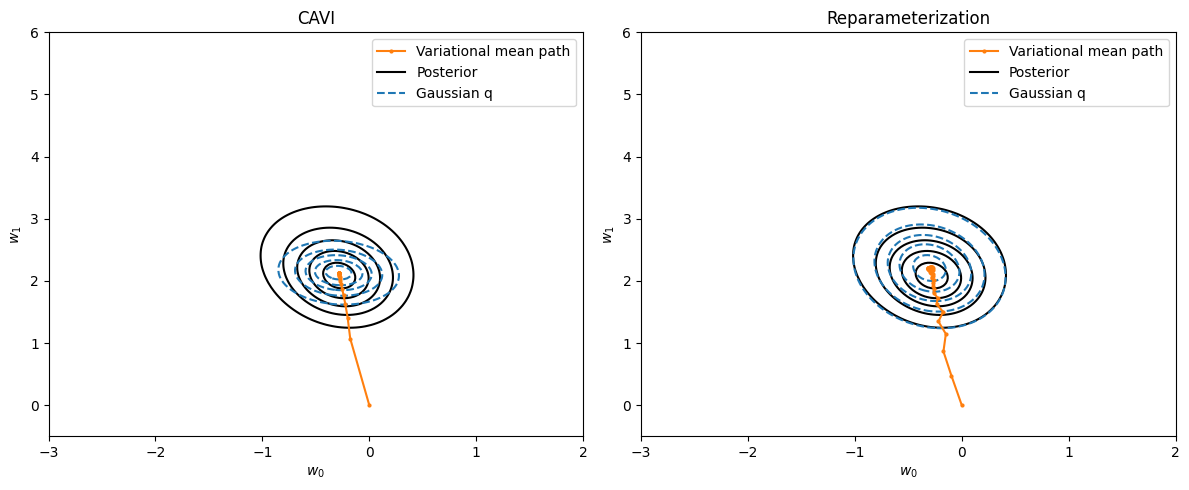

In [9]:
# ============================================================
# 5. Compare variational approximations and mean trajectories
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name, m, L, means in zip(axes, ['CAVI', 'Reparameterization'],
                                [m_cavi, m_rp], [L_cavi, L_rp], [cavi_means, rp_means]):
    q = torch.distributions.MultivariateNormal(m, scale_tril=L)
    log_q = q.log_prob(w_grid).reshape(W0.shape)
    q_surface = torch.exp(log_q-log_q.max())
    ax.contour(W0, W1, posterior, levels=[.1, .3, .5, .7, .9], colors='black')
    ax.contour(W0, W1, q_surface, levels=[.1, .3, .5, .7, .9], colors='C0', linestyles='--')
    stride = max(1, len(means)//100)
    ax.plot(means[::stride, 0], means[::stride, 1], '-o', color='C1', markersize=2, label='Variational mean path')
    ax.plot([], [], color='black', label='Posterior')
    ax.plot([], [], '--', color='C0', label='Gaussian q')
    ax.set(title=name, xlabel=r'$w_0$', ylabel=r'$w_1$')
    ax.legend()
plt.tight_layout(); plt.show()

### Samples from the fitted approximations

Once optimization finishes, draw independent Gaussian samples from each $q$. These are **approximate posterior samples**, not samples from the exact posterior. No burn-in or accept/reject step is needed.

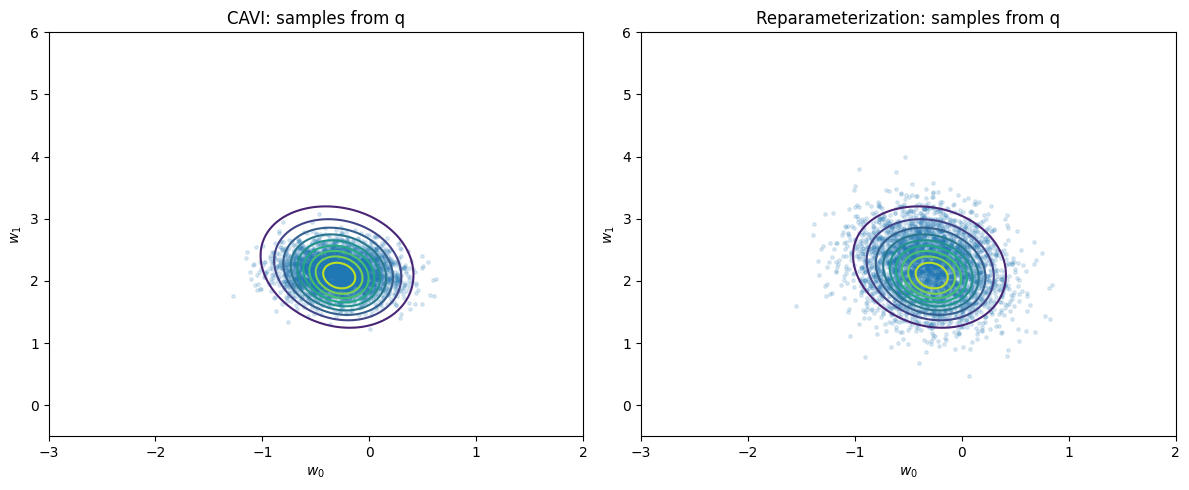

In [10]:
torch.manual_seed(20)
num_samples = 4000
shared_eps = torch.randn(num_samples, D, dtype=phi.dtype)
cavi_samples = m_cavi + shared_eps @ L_cavi.T
rp_samples = m_rp + shared_eps @ L_rp.T

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, samples, name in zip(axes, [cavi_samples, rp_samples], ['CAVI', 'Reparameterization']):
    ax.contour(W0, W1, posterior, levels=10)
    ax.scatter(samples[:, 0], samples[:, 1], s=6, alpha=.15)
    ax.set(title=f'{name}: samples from q', xlabel=r'$w_0$', ylabel=r'$w_1$')
plt.tight_layout(); plt.show()

## 6. Prediction

Bayesian prediction averages predictions over the approximate posterior:
$$p(y_*=1\mid x_*,\mathcal D)\approx\frac1M\sum_{s=1}^M\sigma((w^{(s)})^T\phi_*),\qquad w^{(s)}\sim q.$$
We compare predictive probabilities obtained from **CAVI** and **reparameterization VI**.

In [11]:
# ============================================================
# 6. Posterior predictive distribution
# ============================================================
def posterior_predictive_samples(samples, x_test):
    phi_test = torch.cat([torch.ones(len(x_test), 1, dtype=samples.dtype),
                          x_test.reshape(-1, 1)], dim=1)
    return torch.sigmoid(samples @ phi_test.T)

x_test = torch.linspace(-4, 4, 200, dtype=phi.dtype)
cavi_pred_samples = posterior_predictive_samples(cavi_samples, x_test)
rp_pred_samples = posterior_predictive_samples(rp_samples, x_test)
cavi_pred = cavi_pred_samples.mean(dim=0)
rp_pred = rp_pred_samples.mean(dim=0)

### Posterior predictive mean

Both methods approximate the same model, but they can produce different predictive curves because their optimization objectives differ.

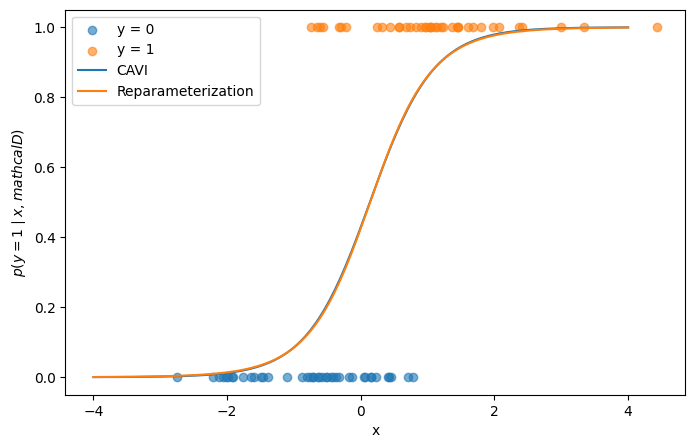

In [12]:
plt.figure(figsize=(8, 5))
plt.scatter(x[y == 0], y[y == 0], label='y = 0', alpha=.6)
plt.scatter(x[y == 1], y[y == 1], label='y = 1', alpha=.6)
plt.plot(x_test, cavi_pred, label='CAVI')
plt.plot(x_test, rp_pred, label='Reparameterization')
plt.xlabel('x'); plt.ylabel(r'$p(y=1\mid x,mathcal D)$')
plt.ylim(-.05, 1.05); plt.legend(); plt.show()

### Predictive uncertainty

Each approximate posterior sample gives a different probability curve:
$$p_*^{(s)}=\sigma((w^{(s)})^T\phi_*).$$
Show the predictive mean and a **pointwise 90% interval of the predicted probability under $q$**. This interval describes parameter uncertainty; it is not a prediction interval for the binary label.

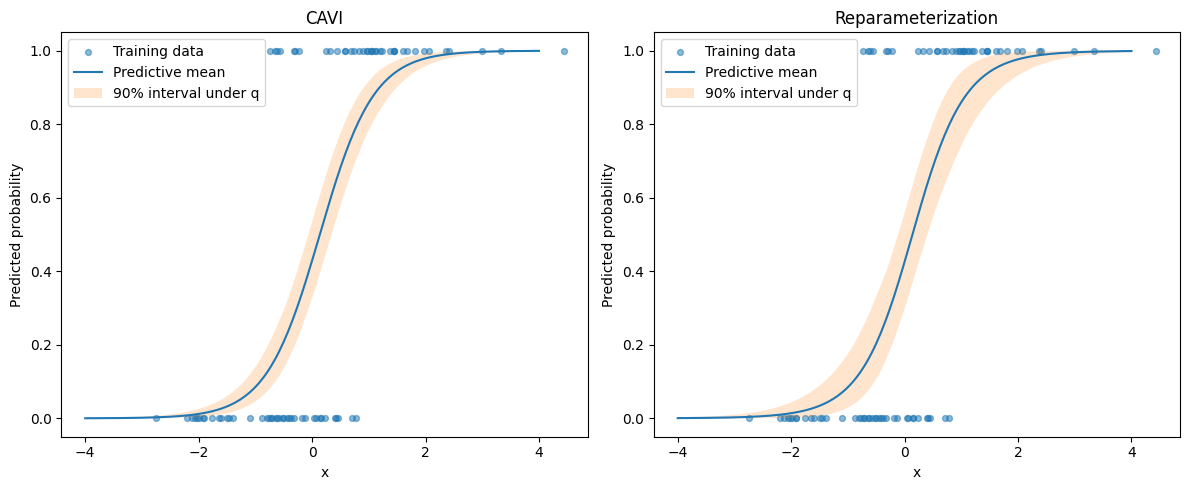

In [13]:
# ============================================================
# Predictive uncertainty under each variational approximation
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, probs, name in zip(axes, [cavi_pred_samples, rp_pred_samples], ['CAVI', 'Reparameterization']):
    mean = probs.mean(dim=0)
    lower = torch.quantile(probs, .05, dim=0)
    upper = torch.quantile(probs, .95, dim=0)
    ax.scatter(x.flatten(), y, alpha=.5, s=18, label='Training data')
    ax.plot(x_test, mean, label='Predictive mean')
    ax.fill_between(x_test, lower, upper, alpha=.2, label='90% interval under q')
    ax.set(title=name, xlabel='x', ylabel='Predicted probability', ylim=(-.05, 1.05))
    ax.legend()
plt.tight_layout(); plt.show()

## Main Observation

Both methods approximate the same Bayesian logistic-regression posterior with a Gaussian distribution.

- **CAVI:** alternate closed-form updates after introducing a quadratic likelihood bound.
- **Reparameterization:** differentiate through Gaussian samples and optimize the original ELBO with stochastic gradients.

Neither Gaussian approximation is guaranteed to equal the exact posterior.

Once the approximation is fitted, both methods use the same prediction rule:
$$\text{sample from }q(w)\quad\Longrightarrow\quad\text{average predictions}.$$

Try changing the sample size, prior standard deviation, or number of Monte Carlo samples used for training. Compare posterior contours and uncertainty intervals, not only the predictive mean.